# Setup

In [2]:
lapply(c('viridis', 'ggthemes', 'skimr'),
       function(pkg_name) { if(! pkg_name %in% installed.packages()) { install.packages(pkg_name)} } )

library(viridis)    # A nice color scheme for plots.
library(ggthemes)   # Common themes to change the look and feel of plots.
library(scales)     # Graphical scales map data to aesthetics in plots.
library(skimr)      # Better summaries of data.
library(lubridate)  # Date library from the tidyverse.
library(tidyverse)  # Data wrangling packages.
library(bigrquery)  # Data extraction from Google BigQuery
library(data.table )

install.packages("pheatmap")
install.packages("pROC")
# Load required libraries
library(dplyr)
library(tidyr)
library(purrr)
library(broom)
library(pheatmap)

## Plot setup.
theme_set(theme_bw(base_size = 14)) # Default theme for plots.

#' Returns a data frame with a y position and a label, for use annotating ggplot boxplots.
#'
#' @param d A data frame.
#' @return A data frame with column y as max and column label as length.
get_boxplot_fun_data <- function(df) {
  return(data.frame(y = max(df), label = stringr::str_c('N = ', length(df))))
}

# Get the bucket name
my_bucket <- Sys.getenv('WORKSPACE_BUCKET')

[[1]]
NULL

[[2]]
NULL

[[3]]
NULL

Installing package into ‘/home/jupyter/packages’
(as ‘lib’ is unspecified)



In [33]:
#name_of_file_in_bucket <- 'All_SDoH_data_domain_filtered_60.csv'
name_of_file_in_bucket <- 'All_SDoH_data_domain_filtered_60.csv'

# Copy the file from current workspace to the bucket
system(paste0("gsutil cp ", my_bucket, "/data/", name_of_file_in_bucket, " ."), intern=T)

# Load the file into a dataframe
sdoh_data  <- read_csv(name_of_file_in_bucket)

name_of_file_in_bucket <- 'adjusted_PRS_scores.csv'

# Copy the file from current workspace to the bucket
system(paste0("gsutil cp ", my_bucket, "/data/", name_of_file_in_bucket, " ."), intern=T)

# Load the file into a dataframe
PRS_df  <- read_csv(name_of_file_in_bucket) 

sdoh_data<-merge(sdoh_data, PRS_df, on="person_id", how="left")

character(0)

Rows: 47487 Columns: 76
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr   (6): SexGender, ancestry_pred, military, healthcare, disabled, sexual_...
dbl  (68): person_id, AIAN, Asian, Black, Mid, Multiple, PI, White, His, rac...
lgl   (1): where_born
date  (1): date_of_birth

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


character(0)

Rows: 135205 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (10): person_id, Asthma_adjusted_score, Afib_adjusted_score, BreastC_adj...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


## Load and merge data

In [4]:
# replace 'test.csv' with the name of the file in your google bucket (don't delete the quotation marks)
name_of_file_in_bucket <- 'Case_Control_df.csv'

# Copy the file from current workspace to the bucket
system(paste0("gsutil cp ", my_bucket, "/data/", name_of_file_in_bucket, " ."), intern=T)

# Load the file into a dataframe
Case_Control_df  <- read_csv(name_of_file_in_bucket)

character(0)

Rows: 226674 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (10): person_id, Asthma, Afib, BreastC, CKD, CHD, HyperC, ProstateC, t2d...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [5]:
merged_data<-merge(sdoh_data, Case_Control_df, on="person_id", how="left")

In [6]:
# replace 'test.csv' with the name of the file in your google bucket (don't delete the quotation marks)
name_of_file_in_bucket <- 'CFA_domain_SDOH_scores'

# Copy the file from current workspace to the bucket
system(paste0("gsutil cp ", my_bucket, "/data/", name_of_file_in_bucket, " ."), intern=T)

# Load the file into a dataframe
CFA_domain_SDOH_scores  <- read_csv(name_of_file_in_bucket)
head(CFA_domain_SDOH_scores)

character(0)

Rows: 47744 Columns: 6
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (6): person_id, SDOH, SCC, NBD, ES, HCAU

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


person_id,SDOH,SCC,NBD,ES,HCAU
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1991141,0.8256857,0.4648203,0.2015249,0.6811465,0.5239146
1268583,0.4666934,0.7103707,0.3320261,0.9704993,0.5838638
1783196,0.3542135,0.4258086,0.2765062,0.4838096,0.2055961
2079342,0.2241988,0.5745591,0.3831465,0.5303097,0.5041900
9994702,0.4156849,0.5032595,0.4944437,0.9299568,0.3969629
7341482,0.1715398,0.5858731,0.3440655,0.9514651,0.6796577


In [7]:
merged_data<-merge(merged_data, CFA_domain_SDOH_scores, on="person_id", how="left")
colnames(merged_data)

[1] "person_id"                     "date_of_birth"                
 [3] "AIAN"                          "Asian"                        
 [5] "Black"                         "Mid"                          
 [7] "Multiple"                      "PI"                           
 [9] "White"                         "His"                          
[11] "race_unknown"                  "SexGender"                    
[13] "age_today"                     "ancestry_pred"                
[15] "PC_1"                          "PC_2"                         
[17] "PC_3"                          "PC_4"                         
[19] "PC_5"                          "PC_6"                         
[21] "PC_7"                          "PC_8"                         
[23] "PC_9"                          "PC_10"                        
[25] "PC_11"                         "PC_12"                        
[27] "PC_13"                         "PC_14"                        
[29] "PC_15"                         "PC_16"                        
[31] "where_born"                    "military"                     
[33] "healthcare"                    "disabled"                     
[35] "sexual_orientation"            "LGBTQIA"                      
[37] "min_date"                      "max_date"                     
[39] "ehr_length"                    "relative_health"              
[41] "record_depth"                  "visit_frequency"              
[43] "age"                           "record_depth_winsorized"      
[45] "visit_frequency_winsorized"    "education"                    
[47] "employment"                    "income"                       
[49] "home_own"                      "number_living"                
[51] "median_adjusted_income"        "number_living_adjusted_income"
[53] "income_adjusted_both"          "health_literacy"              
[55] "housing_quality"               "housing_instability"          
[57] "food_insecurity"               "Walkability"                  
[59] "loneliness"                    "crime_saftey"                 
[61] "npd_scale"                     "nsd_scale"                    
[63] "discrimination"                "health_discrim"               
[65] "social_cohesion"               "stress"                       
[67] "social_support"                "spirituality"                 
[69] "health_coverage"               "health_care_use"              
[71] "delayed_care"                  "afford_care"                  
[73] "worried_pay"                   "respect"                      
[75] "housing_type"                  "per_poverty_threshold"        
[77] "Asthma_adjusted_score"         "Afib_adjusted_score"          
[79] "BreastC_adjusted_score"        "CKD_adjusted_score"           
[81] "CHD_adjusted_score"            "HyperC_adjusted_score"        
[83] "ProstateC_adjusted_score"      "t1d_adjusted_score"           
[85] "t2d_adjusted_score"            "Asthma"                       
[87] "Afib"                          "BreastC"                      
[89] "CKD"                           "CHD"                          
[91] "HyperC"                        "ProstateC"                    
[93] "t2d"                           "t1d"                          
[95] "SDOH"                          "SCC"                          
[97] "NBD"                           "ES"                           
[99] "HCAU"

## Set up lists

In [8]:
diseases<-c("Asthma", "Afib", "BreastC", "CKD", "CHD", "ProstateC", "t2d", "t1d")

# Regressions

## Adjust Right Side of Equation

In [9]:
sdoh_index <- c("ES", "HCAU", "SCC", "NBD", "education", "SDOH")
merged_data$SexGender<-as.factor(merged_data$SexGender)


In [10]:
PRS_index<-c('Asthma_adjusted_score','Afib_adjusted_score','BreastC_adjusted_score',
             'CKD_adjusted_score','CHD_adjusted_score',
             'HyperC_adjusted_score','ProstateC_adjusted_score',
             't1d_adjusted_score','t2d_adjusted_score')

In [58]:
# Define your covariates

covariates <- c("age", "SexGender", "record_depth", "visit_frequency")

# Create adjusted variables using residuals
for (sdoh in sdoh_index) {
  # Build the formula
  formula_str <- paste(sdoh, "~", paste(covariates, collapse = " + "))
  formula_obj <- as.formula(formula_str)

  
  # Fit model and extract residuals
  model <- lm(formula_obj, data = merged_data)
  merged_data[[paste0(sdoh, "_adj")]] <- scale(resid(model))
}

In [12]:
# Create adjusted variables using residuals
for (PRS in PRS_index) {
  # Build the formula
  formula_str <- paste(PRS, "~", paste(covariates, collapse = " + "))
  formula_obj <- as.formula(formula_str)
  
  # Fit model and extract residuals
  model <- lm(formula_obj, data = merged_data)
  merged_data[[paste0(PRS, "_adj")]] <- scale(resid(model))
}

In [13]:
colnames(merged_data)

[1] "person_id"                     "date_of_birth"                
  [3] "AIAN"                          "Asian"                        
  [5] "Black"                         "Mid"                          
  [7] "Multiple"                      "PI"                           
  [9] "White"                         "His"                          
 [11] "race_unknown"                  "SexGender"                    
 [13] "age_today"                     "ancestry_pred"                
 [15] "PC_1"                          "PC_2"                         
 [17] "PC_3"                          "PC_4"                         
 [19] "PC_5"                          "PC_6"                         
 [21] "PC_7"                          "PC_8"                         
 [23] "PC_9"                          "PC_10"                        
 [25] "PC_11"                         "PC_12"                        
 [27] "PC_13"                         "PC_14"                        
 [29] "PC_15"                         "PC_16"                        
 [31] "where_born"                    "military"                     
 [33] "healthcare"                    "disabled"                     
 [35] "sexual_orientation"            "LGBTQIA"                      
 [37] "min_date"                      "max_date"                     
 [39] "ehr_length"                    "relative_health"              
 [41] "record_depth"                  "visit_frequency"              
 [43] "age"                           "record_depth_winsorized"      
 [45] "visit_frequency_winsorized"    "education"                    
 [47] "employment"                    "income"                       
 [49] "home_own"                      "number_living"                
 [51] "median_adjusted_income"        "number_living_adjusted_income"
 [53] "income_adjusted_both"          "health_literacy"              
 [55] "housing_quality"               "housing_instability"          
 [57] "food_insecurity"               "Walkability"                  
 [59] "loneliness"                    "crime_saftey"                 
 [61] "npd_scale"                     "nsd_scale"                    
 [63] "discrimination"                "health_discrim"               
 [65] "social_cohesion"               "stress"                       
 [67] "social_support"                "spirituality"                 
 [69] "health_coverage"               "health_care_use"              
 [71] "delayed_care"                  "afford_care"                  
 [73] "worried_pay"                   "respect"                      
 [75] "housing_type"                  "per_poverty_threshold"        
 [77] "Asthma_adjusted_score"         "Afib_adjusted_score"          
 [79] "BreastC_adjusted_score"        "CKD_adjusted_score"           
 [81] "CHD_adjusted_score"            "HyperC_adjusted_score"        
 [83] "ProstateC_adjusted_score"      "t1d_adjusted_score"           
 [85] "t2d_adjusted_score"            "Asthma"                       
 [87] "Afib"                          "BreastC"                      
 [89] "CKD"                           "CHD"                          
 [91] "HyperC"                        "ProstateC"                    
 [93] "t2d"                           "t1d"                          
 [95] "SDOH"                          "SCC"                          
 [97] "NBD"                           "ES"                           
 [99] "HCAU"                          "ES_adj"                       
[101] "HCAU_adj"                      "SCC_adj"                      
[103] "NBD_adj"                       "education_adj"                
[105] "SDOH_adj"                      "Asthma_adjusted_score_adj"    
[107] "Afib_adjusted_score_adj"       "BreastC_adjusted_score_adj"   
[109] "CKD_adjusted_score_adj"        "CHD_adjusted_score_adj"       
[111] "HyperC_adjusted_score_adj"     "ProstateC_adjusted_score_adj" 
[113] "t1d_adjusted_score_adj"        "t2d_adjusted_score_adj"

## Models

In [15]:
library(dplyr)
library(broom)
library(pROC)

# Function to generate the "Genetic" model formula for disease-domain pairs
generate_formulas <- function(disease) {
  score <- paste0(disease, "_adjusted_score_adj")
  # Return the Genetic model formula
  as.formula(paste(disease, "~", paste(c(score), collapse = " + ")))
}



Type 'citation("pROC")' for a citation.


Attaching package: ‘pROC’


The following objects are masked from ‘package:stats’:

    cov, smooth, var




## Auc

In [16]:
library(dplyr)
library(broom)
library(pROC)

# SDoH variables
sdoh_var <- c("ES_adj", "HCAU_adj", "SCC_adj", "NBD_adj", "education_adj", "SDOH_adj")

fit_by_quantiles <- function(formula, disease, sdoh_var, data, n_quantiles = 5) {
  
  # Create quantile groups
  data <- data %>%
    filter(!is.na(.data[[sdoh_var]])) %>%
    mutate(quantile_group = ntile(.data[[sdoh_var]], n_quantiles))

  # Fit models for each quantile group
  results <- data %>%
    group_by(quantile_group) %>%
    group_map(~ {

      # Fit the model
      model <- glm(formula, data = .x, family = binomial(link = "logit"))
      
      # Calculate predictions and AUC
      preds <- predict(model, type = "response")
      actuals <- model$y

      if (length(unique(actuals)) > 1) {
        roc_obj <- roc(actuals, preds, quiet = TRUE)
        auc <- as.numeric(roc_obj$auc)
        auc_ci <- ci.auc(roc_obj)
      } else {
        auc <- NA
        auc_ci <- c(NA, NA, NA)
      }
      
      # Extract model coefficients
      tidy(model) %>%
        mutate(
          Disease = disease,
          Quantile_Group = .y$quantile_group,  # Properly carried from the group key
          SDoH_Variable = sdoh_var,
          AUC = auc,
          AUC_CI_Lower = auc_ci[1],
          AUC_CI_Upper = auc_ci[3]
        )
    }) %>%
    bind_rows()

  return(results)
}


# Generate combinations of diseases and SDoH variables
combinations <- expand_grid(
  disease = unlist(diseases),
  sdoh_var = sdoh_var
)

# Step 2: Generate formulas and fit models
results <- combinations %>%
  rowwise() %>%
  mutate(
    formula = list(generate_formulas(disease)),  # Generate formula for each disease
    quantile_results = list(fit_by_quantiles(formula, disease, sdoh_var, merged_data))  # Fit models by quantiles
  ) %>%
  ungroup() %>%
  select(quantile_results) %>%
  unnest(quantile_results)

# Print results
head(results)


Warning message:
“There was 1 warning in `mutate()`.
ℹ In argument: `quantile_results = list(fit_by_quantiles(formula, disease,
  sdoh_var, merged_data))`.
ℹ In row 1.
Caused by warning:
! Using one column matrices in `filter()` was deprecated in dplyr 1.1.0.
ℹ Please use one dimensional logical vectors instead.”


term,estimate,std.error,statistic,p.value,Disease,Quantile_Group,SDoH_Variable,AUC,AUC_CI_Lower,AUC_CI_Upper
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<int>,<chr>,<dbl>,<dbl>,<dbl>
(Intercept),-0.3534260,0.03929448,-8.994291,2.377625e-19,Asthma,1,ES_adj,0.5676735,0.5459837,0.5893634
Asthma_adjusted_score_adj,0.2603900,0.04030608,6.460315,1.044850e-10,Asthma,1,ES_adj,0.5676735,0.5459837,0.5893634
(Intercept),-0.3699263,0.04019196,-9.203989,3.449035e-20,Asthma,2,ES_adj,0.5721598,0.5500217,0.5942980
Asthma_adjusted_score_adj,0.2469523,0.03992039,6.186118,6.166367e-10,Asthma,2,ES_adj,0.5721598,0.5500217,0.5942980
(Intercept),-0.5420558,0.04115037,-13.172562,1.262391e-39,Asthma,3,ES_adj,0.5407972,0.5178171,0.5637774
Asthma_adjusted_score_adj,0.1524454,0.04171689,3.654285,2.578997e-04,Asthma,3,ES_adj,0.5407972,0.5178171,0.5637774


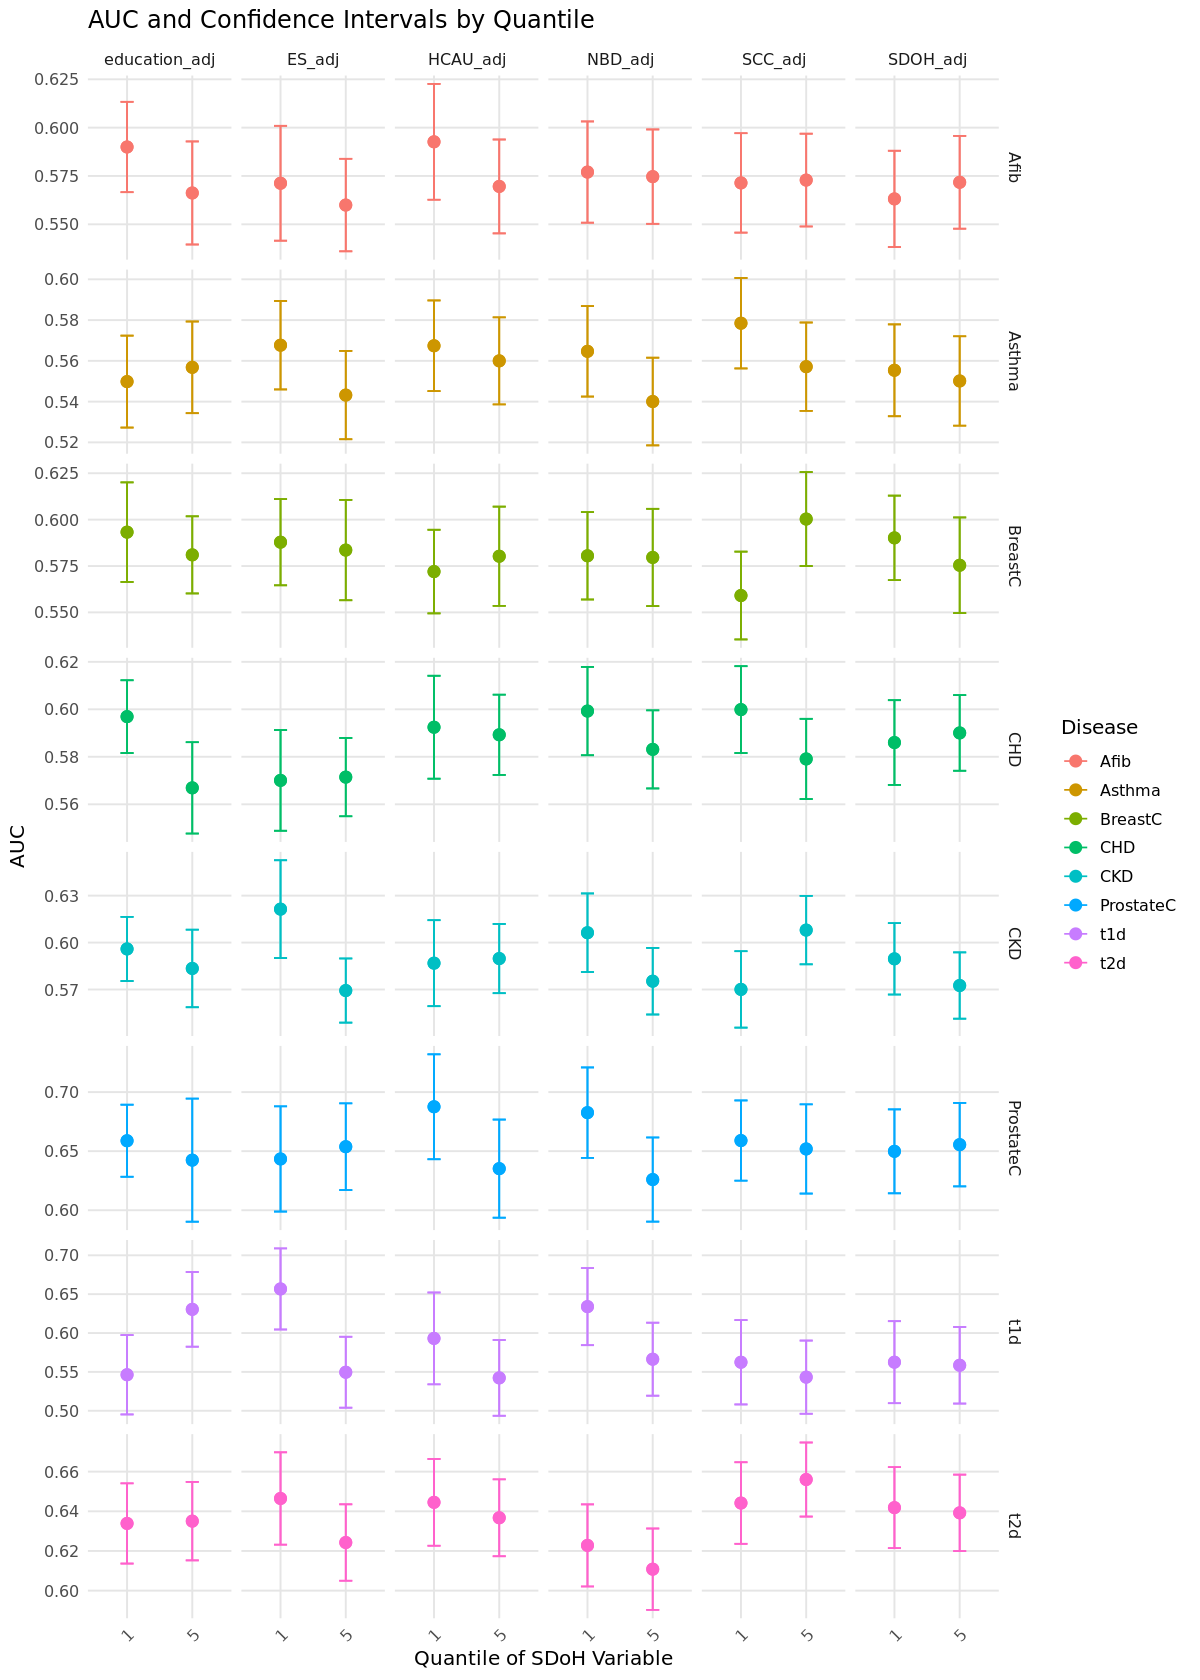

In [17]:
library(ggplot2)
library(dplyr)

results<-results[results$Quantile_Group %in% c(1,5), ]


# Example plotting function
plot_auc_by_quantile <- function(results) {
  # Ensure results data is in the expected format
  results <- results %>%
    mutate(
      Quantile_Group = factor(Quantile_Group, levels = sort(unique(Quantile_Group))),
      Disease = factor(Disease),
      SDoH_Variable = factor(SDoH_Variable)
    )
  
  # Create the plot
  ggplot(results, aes(x = Quantile_Group, y = AUC, group = Disease)) +
    geom_point(aes(color = Disease), size = 3) +  # Points for AUC
    geom_errorbar(aes(ymin = AUC_CI_Lower, ymax = AUC_CI_Upper, color = Disease), width = 0.2) +  # Error bars for CI
    facet_grid(Disease ~ SDoH_Variable, scales = "free_y") +  # Grid of Disease by SDoH Variable
    labs(
      title = "AUC and Confidence Intervals by Quantile",
      x = "Quantile of SDoH Variable",
      y = "AUC",
      color = "Disease"
    ) +
    theme_minimal(base_size = 12) +
    theme(
      axis.text.x = element_text(angle = 45, hjust = 1),
      panel.grid.major = element_line(color = "gray90"),
      panel.grid.minor = element_blank()
    )
}

#Set plot size for Jupyter Notebook
options(repr.plot.width = 10, repr.plot.height = 14)  # Set width and height

# Generate the plot
plot <- plot_auc_by_quantile(results)
print(plot)


## DeLong's test of significance 

In [18]:
# Function to compute DeLong's test for two quantile groups
perform_delong_test <- function(formula, data, disease, sdoh_var, n_quantiles=5) {
    
  data <- data %>%
    filter(!is.na(.data[[sdoh_var]])) %>%
    mutate(quantile_group = ntile(.data[[sdoh_var]], n_quantiles))
    
  quantile_1 <- data %>% filter(quantile_group == 1)
  quantile_5 <- data %>% filter(quantile_group == 5)
  
  if (nrow(quantile_1) > 0 && nrow(quantile_5) > 0) {
    # Fit models for each quantile
    model1 <- glm(formula, data = quantile_1, family = binomial(link = "logit"))
    model5 <- glm(formula, data = quantile_5, family = binomial(link = "logit"))
    
    # Generate ROC curves
    preds1 <- predict(model1, type = "response")
    preds5 <- predict(model5, type = "response")
    
    roc1 <- roc(model1$y, preds1, quiet = TRUE)
    roc5 <- roc(model5$y, preds5, quiet = TRUE)
    
    # Perform DeLong's test
    test_result <- roc.test(roc1, roc5)
    return(tibble(
      Disease = disease,
      SDoH_Variable = sdoh_var,
      AUC_Quantile_1 = as.numeric(roc1$auc),
      AUC_Quantile_5 = as.numeric(roc5$auc),
      AUC_Difference = as.numeric(roc1$auc - roc5$auc),
      p_value = test_result$p.value
    ))
  } else {
    return(tibble(
      Disease = disease,
      SDoH_Variable = sdoh_var,
      AUC_Quantile_1 = NA,
      AUC_Quantile_5 = NA,
      AUC_Difference = NA,
      p_value = NA
    ))
  }
}

# Apply the test for all disease and SDoH variable combinations
delong_results <- combinations %>%
  rowwise() %>%
  mutate(
      formula = list(generate_formulas(disease)),  # Generate formula for each disease
    delong_test = list(
      perform_delong_test(formula, merged_data, disease, sdoh_var)
    )
  ) %>%
  unnest(delong_test)



# Step 3: Create a results table
delong_table <- delong_results %>%
  select(Disease, SDoH_Variable, AUC_Quantile_1, AUC_Quantile_5, AUC_Difference, p_value)

# Print the table
print(delong_table)


# A tibble: 48 × 6
   Disease SDoH_Variable AUC_Quantile_1 AUC_Quantile_5 AUC_Difference p_value
   <chr>   <chr>                  <dbl>          <dbl>          <dbl>   <dbl>
 1 Asthma  ES_adj                 0.568          0.543        0.0245    0.118
 2 Asthma  HCAU_adj               0.567          0.560        0.00741   0.638
 3 Asthma  SCC_adj                0.578          0.557        0.0213    0.178
 4 Asthma  NBD_adj                0.565          0.540        0.0246    0.118
 5 Asthma  education_adj          0.550          0.557       -0.00699   0.667
 6 Asthma  SDOH_adj               0.555          0.550        0.00524   0.744
 7 Afib    ES_adj                 0.571          0.560        0.0113    0.563
 8 Afib    HCAU_adj               0.593          0.570        0.0231    0.241
 9 Afib    SCC_adj                0.571          0.573       -0.00146   0.935
10 Afib    NBD_adj                0.577          0.575        0.00236   0.897
# ℹ 38 more rows


In [19]:
x_axis_order <- c("SDOH_adj", "SCC_adj", "NBD_adj", "ES_adj", "HCAU_adj", "education_adj")

# First, ensure you only have one value per Disease x SDoH_Variable
# If there are multiple, choose one (e.g., average, max, or first)
delong_table_unique <- delong_table %>%
  group_by(Disease, SDoH_Variable) %>%
  summarise(AUC_Difference = mean(AUC_Difference, na.rm = TRUE), .groups = "drop")

# Pivot wider to form heatmap matrix
heatmap_data <- delong_table_unique %>%
  pivot_wider(
    names_from = SDoH_Variable,
    values_from = AUC_Difference
  ) %>%
  column_to_rownames("Disease")

# Replace NAs with 0 (or another strategy)
heatmap_data[is.na(heatmap_data)] <- 0

# Reorder columns
heatmap_data <- heatmap_data %>%
  select(all_of(x_axis_order))

# View cleaned matrix
print(heatmap_data)



              SDOH_adj      SCC_adj      NBD_adj       ES_adj     HCAU_adj
Afib      -0.008586381 -0.001461203 0.0023573774  0.011265207  0.023067396
Asthma     0.005239118  0.021330246 0.0246220465  0.024473645  0.007408027
BreastC    0.014755877 -0.041236556 0.0008839299  0.004256138 -0.008268496
CHD       -0.004043154  0.020787889 0.0161483152 -0.001383813  0.003182817
CKD        0.017046387 -0.037907648 0.0309746418  0.052025059 -0.002943294
ProstateC -0.005654843  0.007101138 0.0566479193 -0.010381029  0.052388788
t1d        0.003954975  0.019171191 0.0676486872  0.107155873  0.050793708
t2d        0.002630005 -0.011867065 0.0119864562  0.022202736  0.007779034
          education_adj
Afib        0.023788435
Asthma     -0.006991317
BreastC     0.012249358
CHD         0.030015992
CKD         0.012463546
ProstateC   0.016423206
t1d        -0.084116553
t2d        -0.001165872


In [20]:
# Step 1: Ensure unique values for each Disease and term combination
delong_table_unique <- delong_table %>%
  group_by(Disease, SDoH_Variable) %>%
  summarize(
    p_value = mean(p_value, na.rm = TRUE),  # Aggregate p-values for consistency
    .groups = "drop"
  ) 

# Step 2: Reshape data for clustering
pvalue_data <- delong_table_unique %>%
  pivot_wider(
    names_from = SDoH_Variable,         # Columns are terms (e.g., PRS, age, SDOH, etc.)
    values_from = p_value  # Fill cells with Effect_Size
  ) %>%
  column_to_rownames("Disease")  # Set diseases as rownames


# Ensure all values are numeric and handle NA values
pvalue_data <- pvalue_data %>%
  mutate(across(everything(), as.numeric))  # Convert all columns to numeric
pvalue_data[is.na(pvalue_data)] <- 0  # Replace NA values with 0 (or another placeholder)
pvalue_data[pvalue_data>0.05/54] <- 0  # Replace NA values with 0 (or another placeholder)


pvalue_data <- pvalue_data %>%
  select(all_of(x_axis_order))  # Reorder columns to match the specified list

pvalue_data

,SDOH_adj,SCC_adj,NBD_adj,ES_adj,HCAU_adj,education_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Afib,0,0,0,0,0,0
Asthma,0,0,0,0,0,0
BreastC,0,0,0,0,0,0
CHD,0,0,0,0,0,0
CKD,0,0,0,0,0,0
ProstateC,0,0,0,0,0,0
t1d,0,0,0,0,0,0
t2d,0,0,0,0,0,0


In [21]:
# Ensure both matrices have the same structure
if (!all(dim(heatmap_data) == dim(pvalue_data))) {
  stop("Error: Dimensions of heatmap_data and pvalue_data do not match.")
}

# Convert pvalue_data to logical mask (TRUE for p-value == 0)
mask <- pvalue_data == 0

# Apply the mask to heatmap_data: Set values to NA where p-value is 0
heatmap_data_labels <- round(heatmap_data, 2)
heatmap_data_labels[mask] <- ""

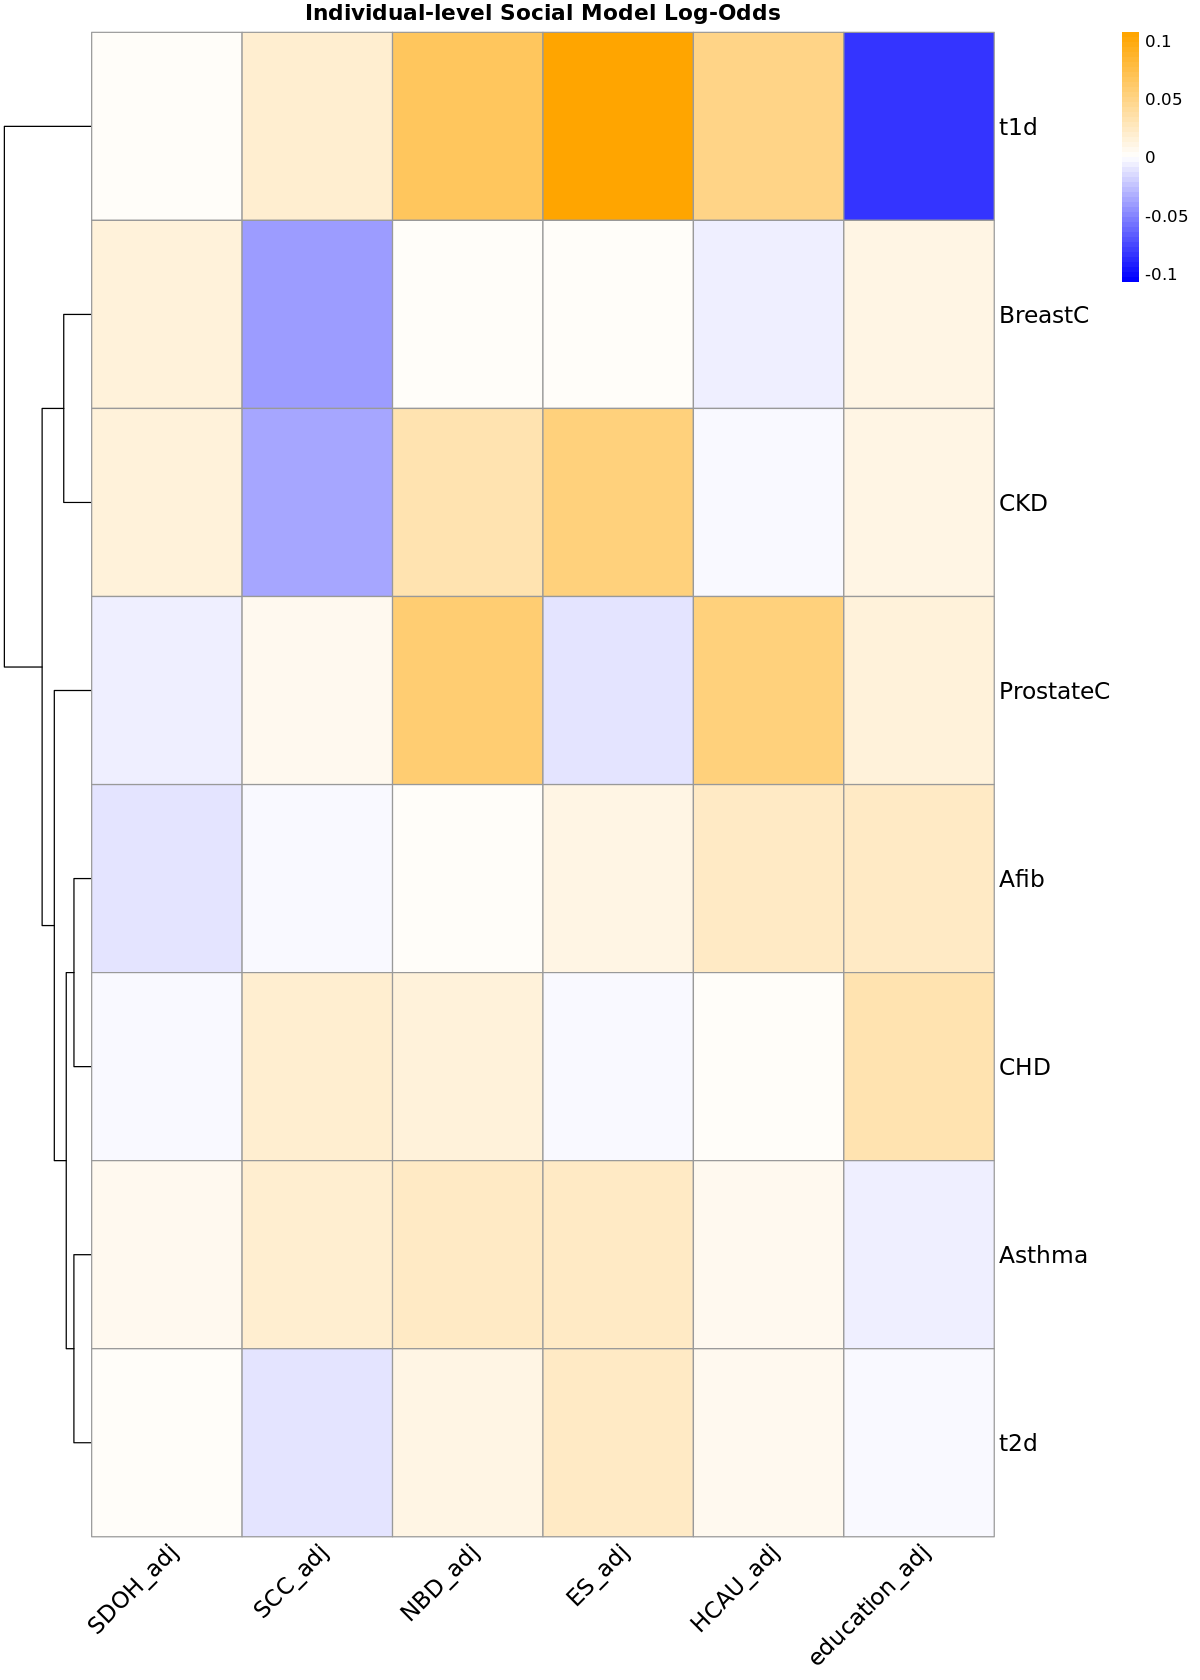

In [22]:
# Step 2: Define a diverging color scale centered at 0
max_abs_value <- max(abs(heatmap_data), na.rm = TRUE)  # Maximum absolute value for symmetric scaling
breaks <- seq(-max_abs_value, max_abs_value, length.out = 51)  # Create breaks for the scale

color_palette <- colorRampPalette(c("blue", "white", "orange"))(length(breaks) - 1)  # Diverging colors


# Step 3: Create a clustering heatmap
map<-pheatmap(
  heatmap_data,
  color = color_palette,  # Diverging color scale
  breaks = breaks,  # Center scale at 0
  cluster_rows = TRUE,  # Cluster diseases
  cluster_cols = FALSE,  # Do not cluster columns (respect custom order)
  main = "Individual-level Social Model Log-Odds",
  fontsize_row = 14,  # Font size for row labels
  fontsize_col = 14,  # Font size for column labels
  display_numbers = heatmap_data_labels,  # Show effect sizes in cells
  number_color = "black",  # Color of the numbers
  number_format = "%.2f",  # Format for numbers in cells
  fontsize_number = 12,
  height = 1,  # Increase vertical size of the heatmap
  width=3,
   angle_col = 45  
)

options(repr.plot.width = 8, repr.plot.height = 4)  # Set width and height

# Save the plot (optional)
ggsave("individual_sdoh_auc_difference_heatmap.png", plot = map, width = 8, height = 4, dpi = 300)

# Area-level AUC

In [23]:
# This query represents dataset "zip_ses_all" for domain "zip_code_socioeconomic" and was generated for All of Us Controlled Tier Dataset v7
dataset_95276326_zip_code_socioeconomic_sql <- paste("
    SELECT
        observation.person_id,
        observation.observation_datetime,
        zip_code.zip3_as_string as zip_code,
        zip_code.fraction_assisted_income as assisted_income,
        zip_code.fraction_high_school_edu as high_school_education,
        zip_code.median_income,
        zip_code.fraction_no_health_ins as no_health_insurance,
        zip_code.fraction_poverty as poverty,
        zip_code.fraction_vacant_housing as vacant_housing,
        zip_code.deprivation_index,
        zip_code.acs as american_community_survey_year 
    FROM
        `zip3_ses_map` zip_code 
    JOIN
        `observation` observation 
            ON CAST(SUBSTR(observation.value_as_string, 0, STRPOS(observation.value_as_string, '*') - 1) AS INT64) = zip_code.zip3  
    WHERE
        observation.PERSON_ID IN (SELECT
            distinct person_id  
        FROM
            `cb_search_person` cb_search_person  
        WHERE
            cb_search_person.person_id IN (SELECT
                person_id 
            FROM
                `cb_search_person` p 
            WHERE
                has_whole_genome_variant = 1 ) 
            AND cb_search_person.person_id IN (SELECT
                person_id 
            FROM
                `cb_search_person` p 
            WHERE
                has_ehr_data = 1 ) ) 
        AND observation_source_concept_id = 1585250 
        AND observation.value_as_string NOT LIKE 'Res%'", sep="")

# Formulate a Cloud Storage destination path for the data exported from BigQuery.
# NOTE: By default data exported multiple times on the same day will overwrite older copies.
#       But data exported on a different days will write to a new location so that historical
#       copies can be kept as the dataset definition is changed.
zip_code_socioeconomic_95276326_path <- file.path(
  Sys.getenv("WORKSPACE_BUCKET"),
  "bq_exports",
  Sys.getenv("OWNER_EMAIL"),
  strftime(lubridate::now(), "%Y%m%d"),  # Comment out this line if you want the export to always overwrite.
  "zip_code_socioeconomic_95276326",
  "zip_code_socioeconomic_95276326_*.csv")
message(str_glue('The data will be written to {zip_code_socioeconomic_95276326_path}. Use this path when reading ',
                 'the data into your notebooks in the future.'))

# Perform the query and export the dataset to Cloud Storage as CSV files.
# NOTE: You only need to run `bq_table_save` once. After that, you can
#       just read data from the CSVs in Cloud Storage.
bq_table_save(
  bq_dataset_query(Sys.getenv("WORKSPACE_CDR"), dataset_95276326_zip_code_socioeconomic_sql, billing = Sys.getenv("GOOGLE_PROJECT")),
  zip_code_socioeconomic_95276326_path,
  destination_format = "CSV")


# Read the data directly from Cloud Storage into memory.
# NOTE: Alternatively you can `gsutil -m cp {zip_code_socioeconomic_95276326_path}` to copy these files
#       to the Jupyter disk.
read_bq_export_from_workspace_bucket <- function(export_path) {
  col_types <- cols(zip3_as_string = col_character())
  bind_rows(
    map(system2('gsutil', args = c('ls', export_path), stdout = TRUE, stderr = TRUE),
        function(csv) {
          message(str_glue('Loading {csv}.'))
          chunk <- read_csv(pipe(str_glue('gsutil cat {csv}')), col_types = col_types, show_col_types = FALSE)
          if (is.null(col_types)) {
            col_types <- spec(chunk)
          }
          chunk
        }))
}
zip_code_socioeconomic_df <- read_bq_export_from_workspace_bucket(zip_code_socioeconomic_95276326_path)


The data will be written to gs://fc-secure-784622b3-a3b0-42a1-a555-372ab8841bd6/bq_exports/micah_hysong@researchallofus.org/20250513/zip_code_socioeconomic_95276326/zip_code_socioeconomic_95276326_*.csv. Use this path when reading the data into your notebooks in the future.

Loading gs://fc-secure-784622b3-a3b0-42a1-a555-372ab8841bd6/bq_exports/micah_hysong@researchallofus.org/20250513/zip_code_socioeconomic_95276326/zip_code_socioeconomic_95276326_000000000000.csv.

Warning message:
“The following named parsers don't match the column names: zip3_as_string”


In [24]:
# replace 'test.csv' with the name of the file in your google bucket (don't delete the quotation marks)
name_of_file_in_bucket <- 'Demographic_and_ancestry_covariates.csv'

# Copy the file from current workspace to the bucket
system(paste0("gsutil cp ", my_bucket, "/data/", name_of_file_in_bucket, " ."), intern=T)

# Load the file into a dataframe
demo  <- read_csv(name_of_file_in_bucket)

character(0)

Rows: 135205 Columns: 47
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr   (9): SexGender, ancestry_pred, income, education, where_born, military...
dbl  (27): person_id, race_unknown, age_today, PC_1, PC_2, PC_3, PC_4, PC_5,...
lgl   (8): AIAN, Asian, Black, Mid, Multiple, PI, White, His
date  (3): date_of_birth, min_date, max_date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [34]:
merged_data<-merge(zip_code_socioeconomic_df, demo, on="person_id", how="left")
merged_data<-merge(merged_data, Case_Control_df, on="person_id", how="left")
merged_data<-merge(merged_data, PRS_df, on="person_id", how="left")
merged_data<-rename(merged_data, age = age_at_last_event)
colnames(merged_data)

[1] "person_id"                      "observation_datetime"          
 [3] "zip_code"                       "assisted_income"               
 [5] "high_school_education"          "median_income"                 
 [7] "no_health_insurance"            "poverty"                       
 [9] "vacant_housing"                 "deprivation_index"             
[11] "american_community_survey_year" "date_of_birth"                 
[13] "AIAN"                           "Asian"                         
[15] "Black"                          "Mid"                           
[17] "Multiple"                       "PI"                            
[19] "White"                          "His"                           
[21] "race_unknown"                   "SexGender"                     
[23] "age_today"                      "ancestry_pred"                 
[25] "PC_1"                           "PC_2"                          
[27] "PC_3"                           "PC_4"                          
[29] "PC_5"                           "PC_6"                          
[31] "PC_7"                           "PC_8"                          
[33] "PC_9"                           "PC_10"                         
[35] "PC_11"                          "PC_12"                         
[37] "PC_13"                          "PC_14"                         
[39] "PC_15"                          "PC_16"                         
[41] "income"                         "education"                     
[43] "where_born"                     "military"                      
[45] "healthcare"                     "disabled"                      
[47] "sexual_orientation"             "LGBTQIA"                       
[49] "min_date"                       "max_date"                      
[51] "ehr_length"                     "relative_health"               
[53] "record_depth"                   "visit_frequency"               
[55] "age"                            "record_depth_winsorized"       
[57] "visit_frequency_winsorized"     "Asthma"                        
[59] "Afib"                           "BreastC"                       
[61] "CKD"                            "CHD"                           
[63] "HyperC"                         "ProstateC"                     
[65] "t2d"                            "t1d"                           
[67] "Asthma_adjusted_score"          "Afib_adjusted_score"           
[69] "BreastC_adjusted_score"         "CKD_adjusted_score"            
[71] "CHD_adjusted_score"             "HyperC_adjusted_score"         
[73] "ProstateC_adjusted_score"       "t1d_adjusted_score"            
[75] "t2d_adjusted_score"

In [35]:
sdoh_index<-c('assisted_income', 'high_school_education', 'median_income', 
           'no_health_insurance', 'poverty', 'vacant_housing', 'deprivation_index')

PRS_index<-c('Asthma_adjusted_score','Afib_adjusted_score','BreastC_adjusted_score',
             'CKD_adjusted_score','CHD_adjusted_score',
             'HyperC_adjusted_score','ProstateC_adjusted_score',
             't1d_adjusted_score','t2d_adjusted_score')

In [36]:
sdoh_var<-c('assisted_income', 'high_school_education', 'median_income', 
           'no_health_insurance', 'poverty', 'vacant_housing', 'deprivation_index')

# Min-Max Normalization
normalize_min_max <- function(x) {
  (x - min(x, na.rm = TRUE)) / (max(x, na.rm = TRUE) - min(x, na.rm = TRUE))
}

merged_data$median_income<-1-merged_data$median_income
merged_data$high_school_education<-1-merged_data$high_school_education

# Apply normalization to the selected columns
merged_data <- merged_data %>%
  mutate(across(all_of(sdoh_var), normalize_min_max))

In [59]:
#sensitivity analysis
#covariates<-c(covariates, "PC_1", "PC_2", "PC_3", "PC_4", "PC_5", "PC_6", "PC_7", "PC_8", "PC_9", "PC_10")
##

# Create adjusted variables using residuals
for (sdoh in sdoh_index) {
  # Build the formula
  formula_str <- paste(sdoh, "~", paste(covariates, collapse = " + "))
  formula_obj <- as.formula(formula_str)

  
  # Fit model and extract residuals
  model <- lm(formula_obj, data = merged_data)
  merged_data[[paste0(sdoh, "_adj")]] <- scale(resid(model))
}

# Create adjusted variables using residuals
for (PRS in PRS_index) {
  # Build the formula
  formula_str <- paste(PRS, "~", paste(covariates, collapse = " + "))
  formula_obj <- as.formula(formula_str)
  
  # Fit model and extract residuals
  model <- lm(formula_obj, data = merged_data)
  merged_data[[paste0(PRS, "_adj")]] <- scale(resid(model))
}

In [60]:
sdoh_var<-c('assisted_income_adj', 'high_school_education_adj', 'median_income_adj', 
           'no_health_insurance_adj', 'poverty_adj', 'vacant_housing_adj', 'deprivation_index_adj')

# Generate combinations of diseases and SDoH variables
combinations <- expand_grid(
  disease = unlist(diseases),
  sdoh_var = sdoh_var
)

# Step 2: Generate formulas and fit models
results <- combinations %>%
  rowwise() %>%
  mutate(
    formula = list(generate_formulas(disease)),  # Generate formula for each disease
    quantile_results = list(fit_by_quantiles(formula, disease, sdoh_var, merged_data))  # Fit models by quantiles
  ) %>%
  ungroup() %>%
  select(quantile_results) %>%
  unnest(quantile_results)

# Print results
head(results)

term,estimate,std.error,statistic,p.value,Disease,Quantile_Group,SDoH_Variable,AUC,AUC_CI_Lower,AUC_CI_Upper
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<int>,<chr>,<dbl>,<dbl>,<dbl>
(Intercept),-0.4911707,0.02361945,-20.795183,4.785238e-96,Asthma,1,assisted_income_adj,0.5634396,0.5503200,0.5765593
Asthma_adjusted_score_adj,0.2256514,0.02382189,9.472441,2.733799e-21,Asthma,1,assisted_income_adj,0.5634396,0.5503200,0.5765593
(Intercept),-0.2969503,0.02312203,-12.842744,9.446633e-38,Asthma,2,assisted_income_adj,0.5575869,0.5446387,0.5705351
Asthma_adjusted_score_adj,0.1936767,0.02317416,8.357440,6.409414e-17,Asthma,2,assisted_income_adj,0.5575869,0.5446387,0.5705351
(Intercept),-0.3677263,0.02431122,-15.125787,1.094836e-51,Asthma,3,assisted_income_adj,0.5411953,0.5275462,0.5548444
Asthma_adjusted_score_adj,0.1443423,0.02472680,5.837483,5.299528e-09,Asthma,3,assisted_income_adj,0.5411953,0.5275462,0.5548444


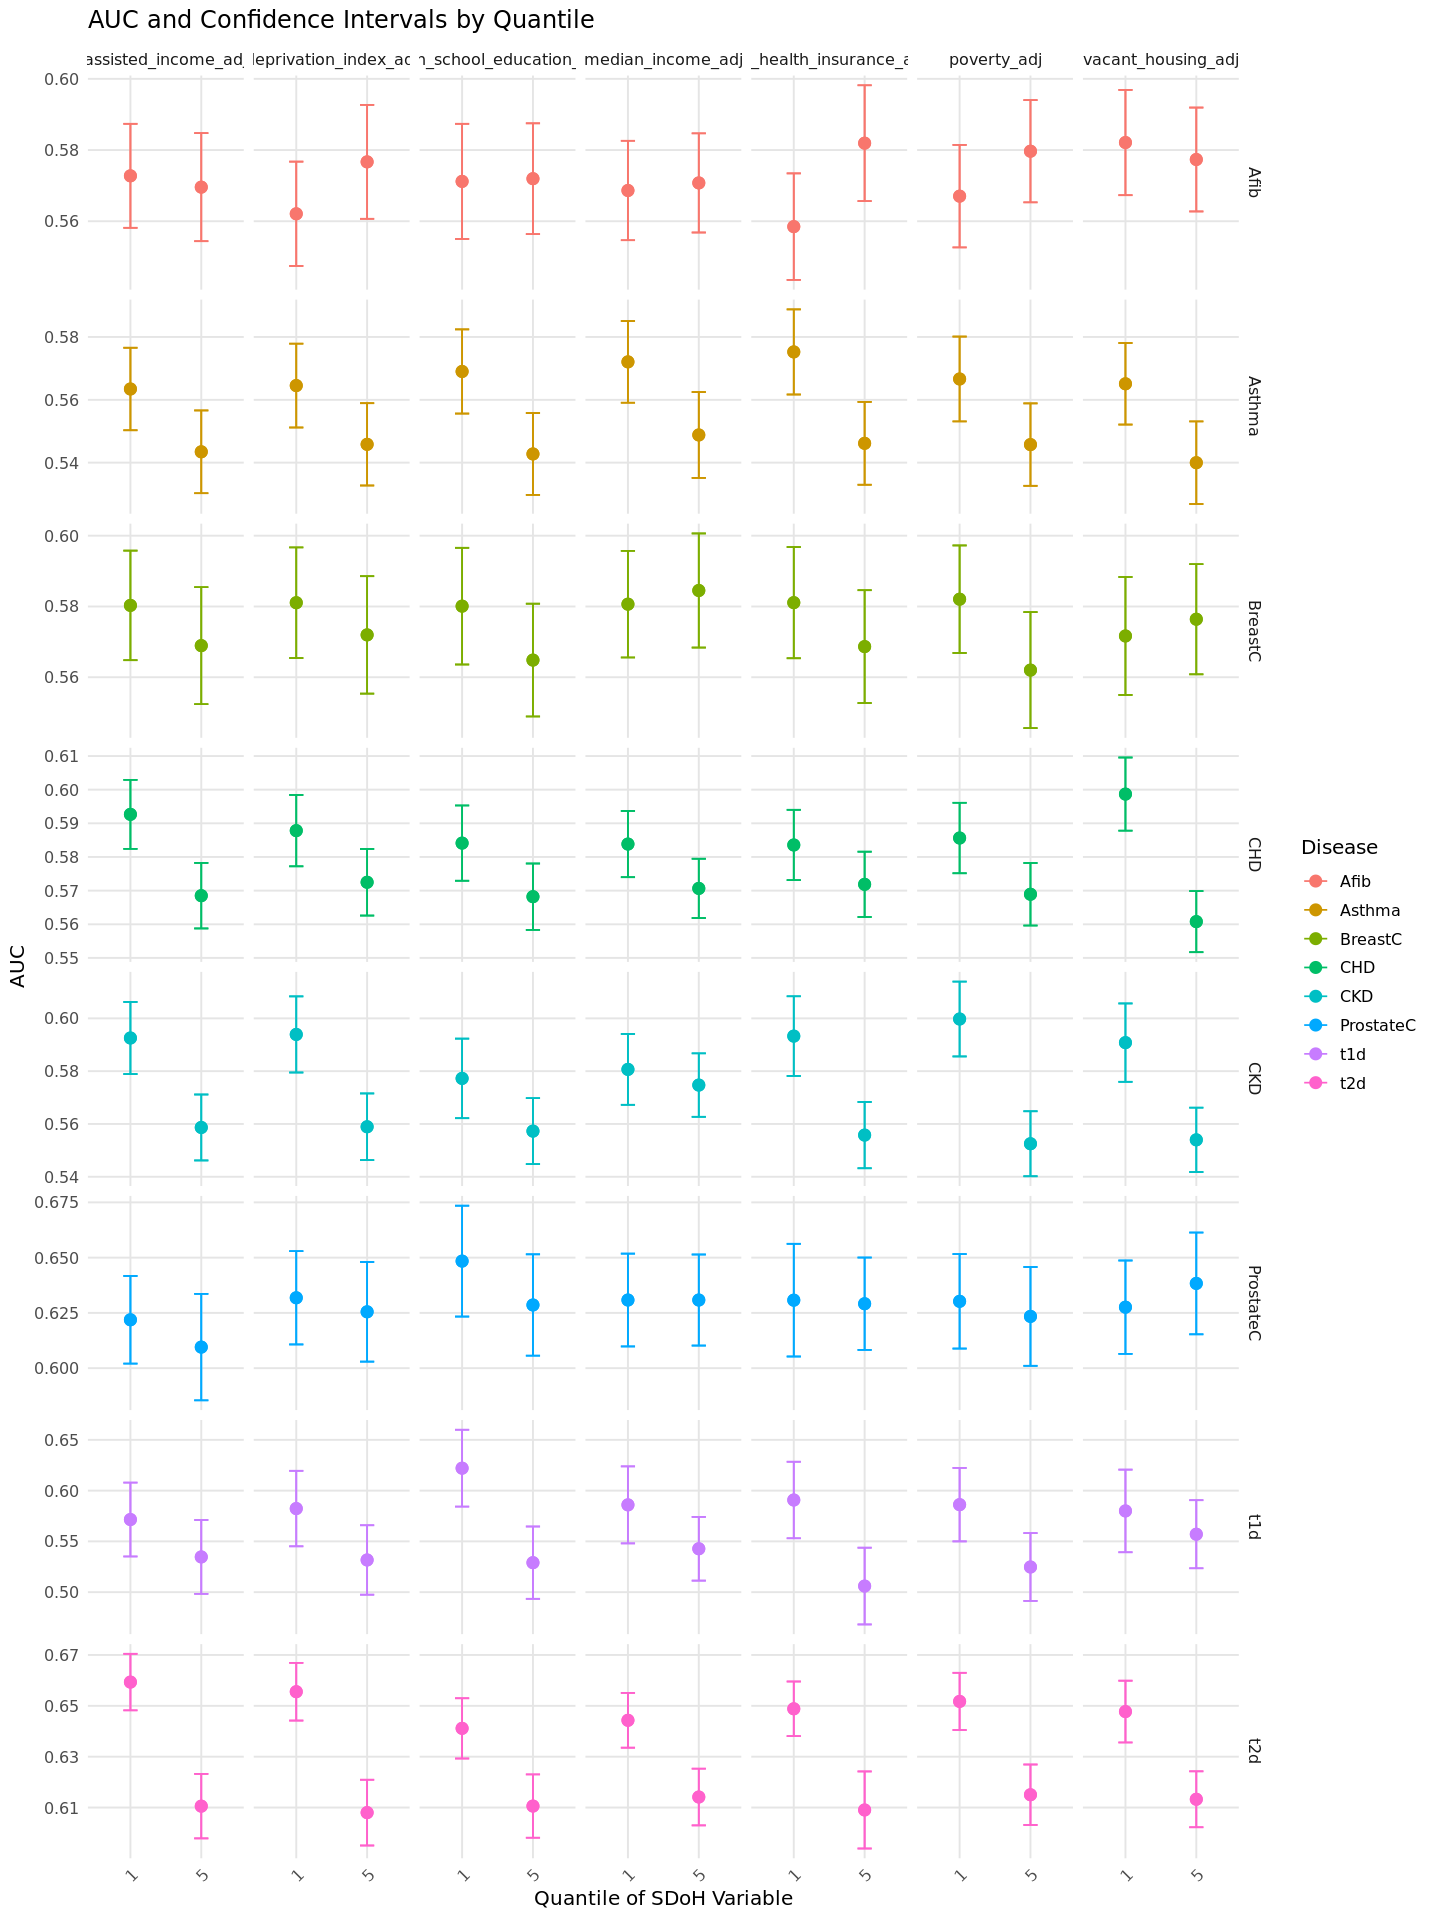

In [61]:
results<-results[results$Quantile_Group %in% c(1,5), ]

# Example plotting function
plot_auc_by_quantile <- function(results) {
  # Ensure results data is in the expected format
  results <- results %>%
    mutate(
      Quantile_Group = factor(Quantile_Group, levels = sort(unique(Quantile_Group))),
      Disease = factor(Disease),
      SDoH_Variable = factor(SDoH_Variable)
    )
  
  # Create the plot
  ggplot(results, aes(x = Quantile_Group, y = AUC, group = Disease)) +
    geom_point(aes(color = Disease), size = 3) +  # Points for AUC
    geom_errorbar(aes(ymin = AUC_CI_Lower, ymax = AUC_CI_Upper, color = Disease), width = 0.2) +  # Error bars for CI
    facet_grid(Disease ~ SDoH_Variable, scales = "free_y") +  # Grid of Disease by SDoH Variable
    labs(
      title = "AUC and Confidence Intervals by Quantile",
      x = "Quantile of SDoH Variable",
      y = "AUC",
      color = "Disease"
    ) +
    theme_minimal(base_size = 12) +
    theme(
      axis.text.x = element_text(angle = 45, hjust = 1),
      panel.grid.major = element_line(color = "gray90"),
      panel.grid.minor = element_blank()
    )
}

#Set plot size for Jupyter Notebook
options(repr.plot.width = 12, repr.plot.height = 16)  # Set width and height

# Generate the plot
plot <- plot_auc_by_quantile(results)
print(plot)

## Delong's test of signfiance 

In [62]:
# Function to compute DeLong's test for two quantile groups
perform_delong_test <- function(formula, data, disease, sdoh_var, n_quantiles=5) {
  
  data <- data %>%
    filter(!is.na(.data[[sdoh_var]])) %>%
    mutate(quantile_group = ntile(.data[[sdoh_var]], n_quantiles))
  
  quantile_1 <- data %>% filter(quantile_group == 1)
  quantile_5 <- data %>% filter(quantile_group == 5)
  
  if (nrow(quantile_1) > 0 && nrow(quantile_5) > 0) {
    model1 <- glm(formula, data = quantile_1, family = binomial(link = "logit"))
    model5 <- glm(formula, data = quantile_5, family = binomial(link = "logit"))
    
    preds1 <- predict(model1, type = "response")
    preds5 <- predict(model5, type = "response")
    
    roc1 <- roc(model1$y, preds1, quiet = TRUE)
    roc5 <- roc(model5$y, preds5, quiet = TRUE)
    
    auc1 <- as.numeric(roc1$auc)
    auc5 <- as.numeric(roc5$auc)
    auc_diff <- auc5 - auc1
    
    percent_diff <- if (!is.na(auc1) && auc1 != 0) {
      100 * auc_diff / auc1
    } else {
      NA
    }
    
    test_result <- roc.test(roc1, roc5)
    
    return(tibble(
      Disease = disease,
      SDoH_Variable = sdoh_var,
      AUC_Quantile_1 = auc1,
      AUC_Quantile_5 = auc5,
      AUC_Difference = auc_diff,
      Percent_Diff_AUC = percent_diff,
      p_value = test_result$p.value
    ))
  } else {
    return(tibble(
      Disease = disease,
      SDoH_Variable = sdoh_var,
      AUC_Quantile_1 = NA,
      AUC_Quantile_5 = NA,
      AUC_Difference = NA,
      Percent_Diff_AUC = NA,
      p_value = NA
    ))
  }
}

# Apply the test for all disease and SDoH variable combinations
delong_results <- combinations %>%
  rowwise() %>%
  mutate(
    formula = list(generate_formulas(disease)),
    delong_test = list(perform_delong_test(formula, merged_data, disease, sdoh_var))
  ) %>%
  unnest(delong_test)

# Final results table
delong_table <- delong_results %>%
  select(Disease, SDoH_Variable, AUC_Quantile_1, AUC_Quantile_5, AUC_Difference, Percent_Diff_AUC, p_value)

# Print results
print(delong_table)


# A tibble: 56 × 7
   Disease SDoH_Variable            AUC_Quantile_1 AUC_Quantile_5 AUC_Difference
   <chr>   <chr>                             <dbl>          <dbl>          <dbl>
 1 Asthma  assisted_income_adj               0.563          0.543      -0.0200  
 2 Asthma  high_school_education_a…          0.569          0.543      -0.0262  
 3 Asthma  median_income_adj                 0.572          0.549      -0.0233  
 4 Asthma  no_health_insurance_adj           0.575          0.546      -0.0291  
 5 Asthma  poverty_adj                       0.567          0.546      -0.0209  
 6 Asthma  vacant_housing_adj                0.565          0.540      -0.0251  
 7 Asthma  deprivation_index_adj             0.565          0.546      -0.0187  
 8 Afib    assisted_income_adj               0.573          0.570      -0.00317 
 9 Afib    high_school_education_a…          0.571          0.572       0.000763
10 Afib    median_income_adj                 0.569          0.571       0.00213 
# ℹ 46 mo

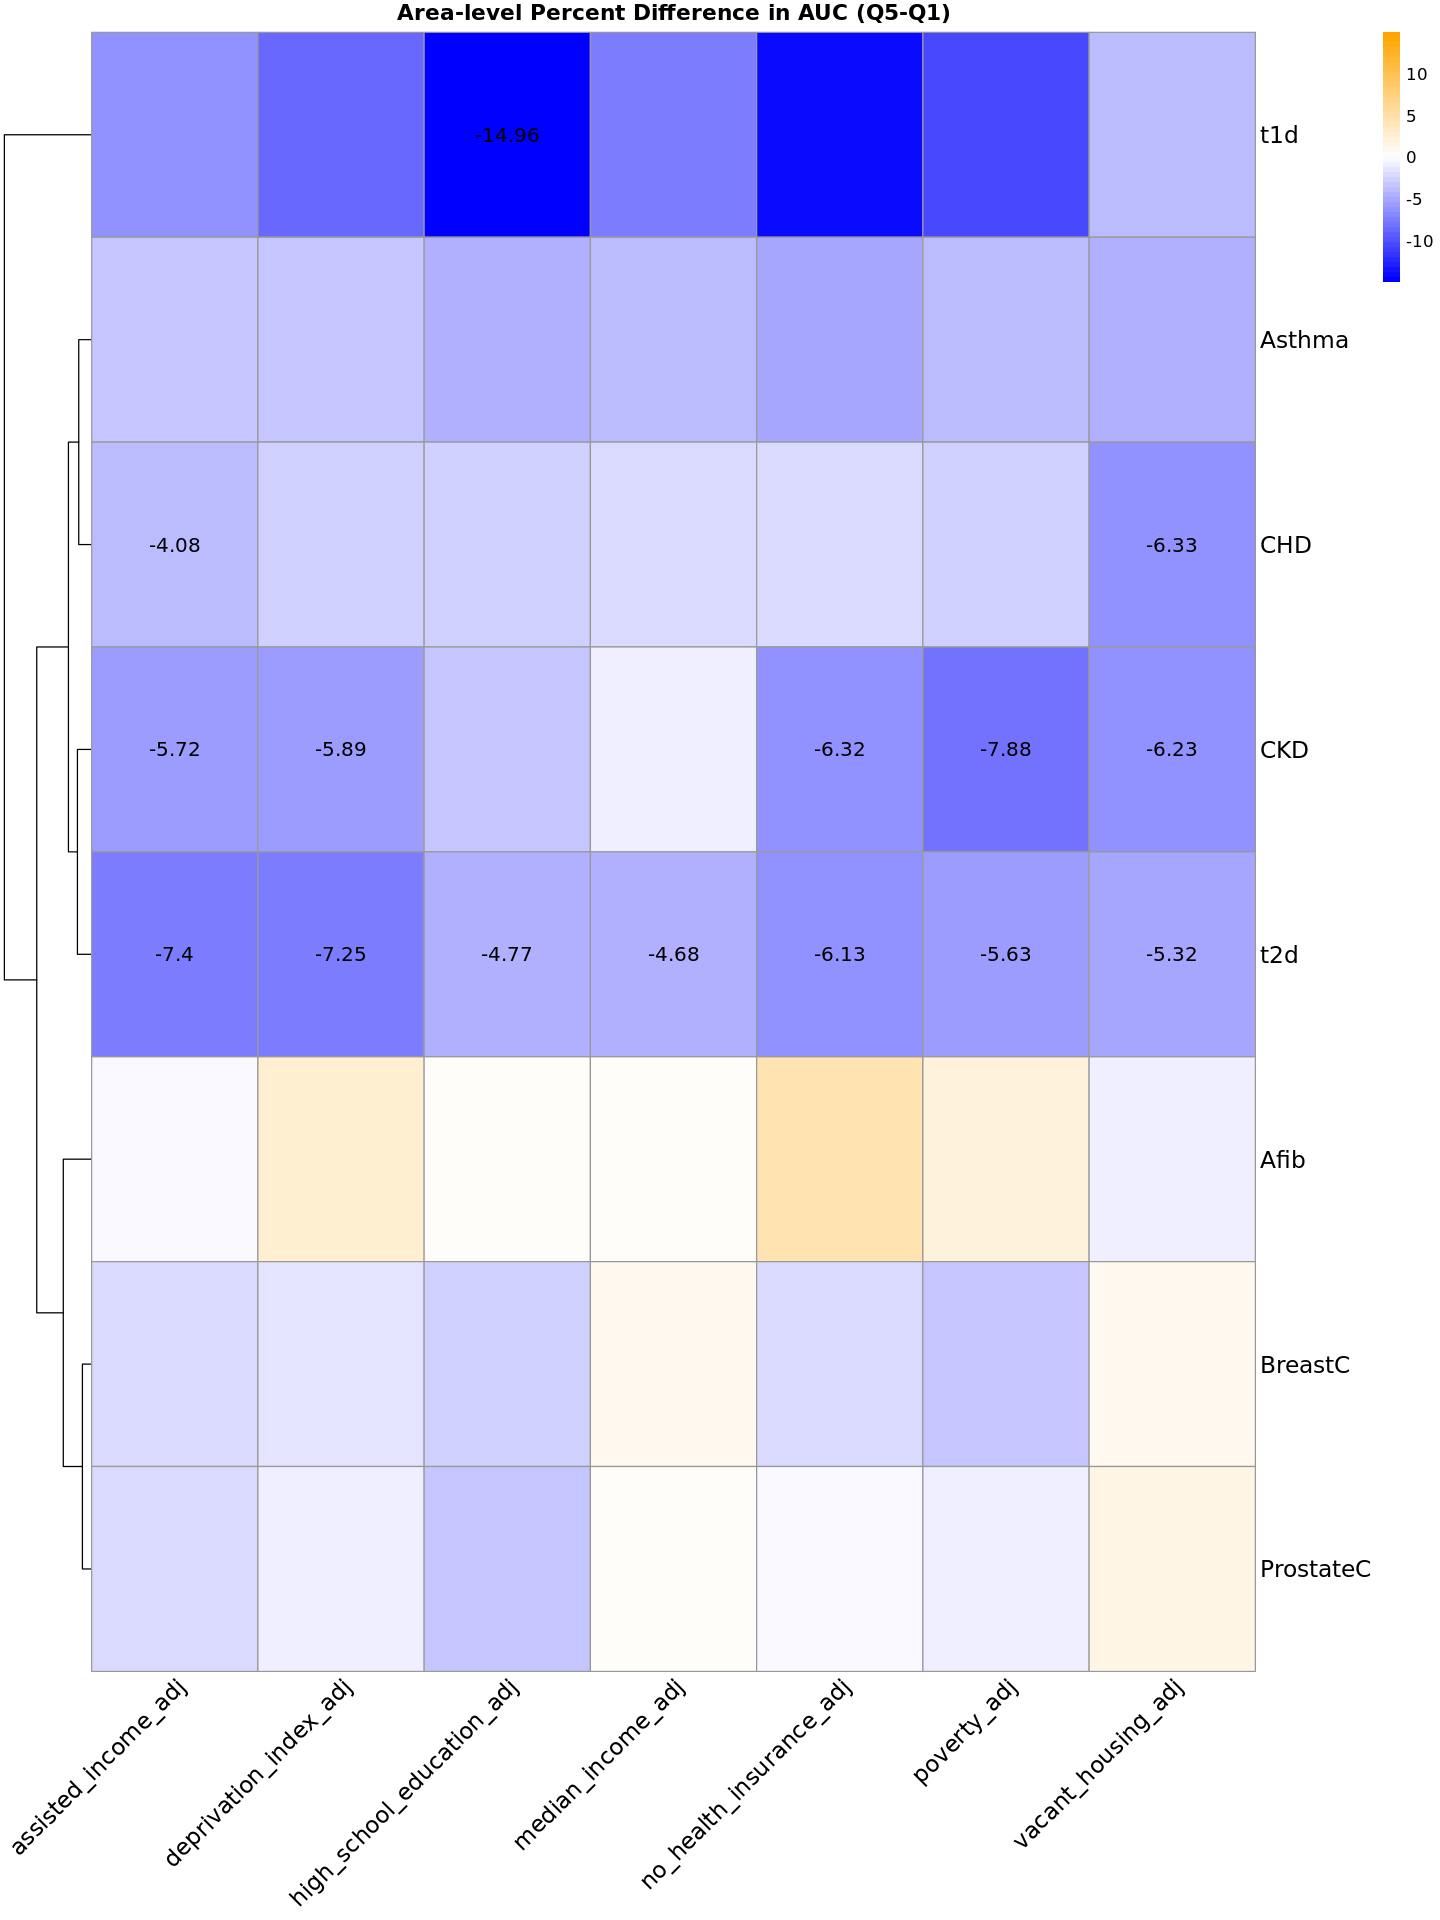

In [63]:

# First, ensure you only have one value per Disease x SDoH_Variable
# If there are multiple, choose one (e.g., average, max, or first)
delong_table_unique <- delong_table %>%
  group_by(Disease, SDoH_Variable) %>%
  summarise(Percent_Diff_AUC = mean(Percent_Diff_AUC, na.rm = TRUE), .groups = "drop")

# Pivot wider to form heatmap matrix
heatmap_data <- delong_table_unique %>%
  pivot_wider(
    names_from = SDoH_Variable,
    values_from = Percent_Diff_AUC
  ) %>%
  column_to_rownames("Disease")

# Replace NAs with 0 (or another strategy)
heatmap_data[is.na(heatmap_data)] <- 0

# Step 1: Ensure unique values for each Disease and term combination
delong_table_unique <- delong_table %>%
  group_by(Disease, SDoH_Variable) %>%
  summarize(
    p_value = mean(p_value, na.rm = TRUE),  # Aggregate p-values for consistency
    .groups = "drop"
  ) 

# Step 2: Reshape data for clustering
pvalue_data <- delong_table_unique %>%
  pivot_wider(
    names_from = SDoH_Variable,         # Columns are terms (e.g., PRS, age, SDOH, etc.)
    values_from = p_value  # Fill cells with Effect_Size
  ) %>%
  column_to_rownames("Disease")  # Set diseases as rownames


# Ensure all values are numeric and handle NA values
pvalue_data <- pvalue_data %>%
  mutate(across(everything(), as.numeric))  # Convert all columns to numeric
pvalue_data[is.na(pvalue_data)] <- 0  # Replace NA values with 0 (or another placeholder)
pvalue_data[pvalue_data>0.05/54] <- 0  # Replace NA values with 0 (or another placeholder)

# Ensure both matrices have the same structure
if (!all(dim(heatmap_data) == dim(pvalue_data))) {
  stop("Error: Dimensions of heatmap_data and pvalue_data do not match.")
}

# Convert pvalue_data to logical mask (TRUE for p-value == 0)
mask <- pvalue_data == 0

# Apply the mask to heatmap_data: Set values to NA where p-value is 0
heatmap_data_labels <- round(heatmap_data, 2)
heatmap_data_labels[mask] <- ""

# Step 2: Define a diverging color scale centered at 0
max_abs_value <- max(abs(heatmap_data), na.rm = TRUE)  # Maximum absolute value for symmetric scaling
breaks <- seq(-max_abs_value, max_abs_value, length.out = 51)  # Create breaks for the scale

color_palette <- colorRampPalette(c("blue", "white", "orange"))(length(breaks) - 1)  # Diverging colors


# Step 3: Create a clustering heatmap
map<-pheatmap(
  heatmap_data,
  color = color_palette,  # Diverging color scale
  breaks = breaks,  # Center scale at 0
  cluster_rows = TRUE,  # Cluster diseases
  cluster_cols = FALSE,  # Do not cluster columns (respect custom order)
  main = "Area-level Percent Difference in AUC (Q5-Q1)",
  fontsize_row = 14,  # Font size for row labels
  fontsize_col = 14,  # Font size for column labels
  display_numbers = heatmap_data_labels,  # Show effect sizes in cells
  number_color = "black",  # Color of the numbers
  number_format = "%.2f",  # Format for numbers in cells
  fontsize_number = 12,
  height = 1,  # Increase vertical size of the heatmap
  width=3,
   angle_col = 45  
)

options(repr.plot.width = 8, repr.plot.height = 8)  # Set width and height

# Save the plot (optional)
ggsave("area_sdoh_Percent_Diff_AUC_heatmap.png", plot = map, width = 8, height = 8, dpi = 300)

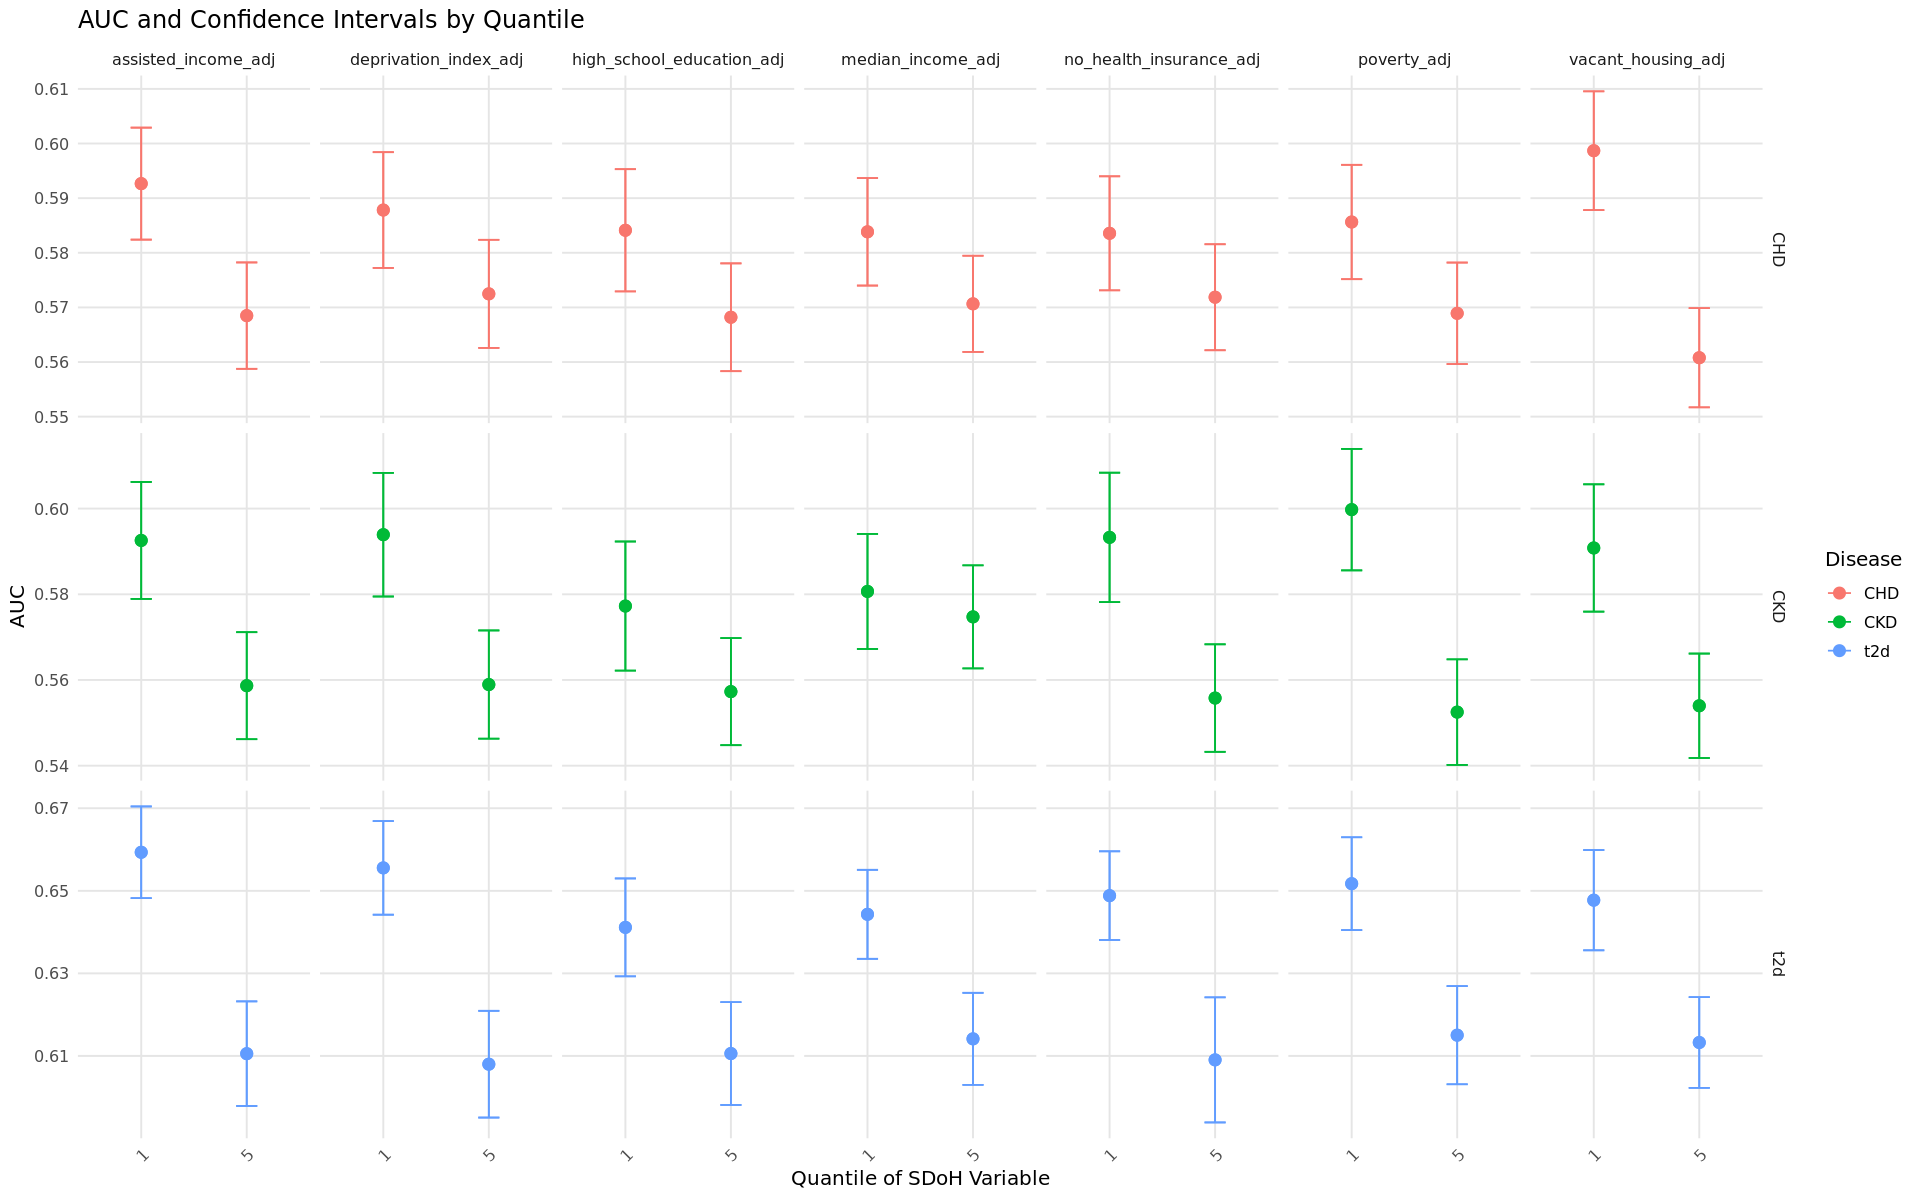

In [64]:
affected_diseases<-c("t2d", "CKD", "CHD")

results<-results[results$Disease %in% affected_diseases, ]
results<-results[results$Quantile_Group %in% c(1,5), ]

# Example plotting function
plot_auc_by_quantile <- function(results) {
  # Ensure results data is in the expected format
  results <- results %>%
    mutate(
      Quantile_Group = factor(Quantile_Group, levels = sort(unique(Quantile_Group))),
      Disease = factor(Disease),
      SDoH_Variable = factor(SDoH_Variable)
    )
  
  # Create the plot
  ggplot(results, aes(x = Quantile_Group, y = AUC, group = Disease)) +
    geom_point(aes(color = Disease), size = 3) +  # Points for AUC
    geom_errorbar(aes(ymin = AUC_CI_Lower, ymax = AUC_CI_Upper, color = Disease), width = 0.2) +  # Error bars for CI
    facet_grid(Disease ~ SDoH_Variable, scales = "free_y") +  # Grid of Disease by SDoH Variable
    labs(
      title = "AUC and Confidence Intervals by Quantile",
      x = "Quantile of SDoH Variable",
      y = "AUC",
      color = "Disease"
    ) +
    theme_minimal(base_size = 12) +
    theme(
      axis.text.x = element_text(angle = 45, hjust = 1),
      panel.grid.major = element_line(color = "gray90"),
      panel.grid.minor = element_blank()
    )
}

#Set plot size for Jupyter Notebook
options(repr.plot.width = 16, repr.plot.height = 10)  # Set width and height

# Generate the plot
plot <- plot_auc_by_quantile(results)
print(plot)